# 06 — CTU-13: Botnet Flow Detection & Graph Feasibility (Corrected)

**Mục tiêu:** chạy thí nghiệm **BOTNET vs NORMAL** trên CTU-13 với tách scenario độc lập; kiểm tra liệu dữ liệu có đủ trường để dựng **host communication graph** và **beaconing** hay không. Không dựng đồ thị giả từ các cột không có IP/timestamp.

**Phương pháp nghiên cứu:**
- Dữ liệu từ Notebook 02: 13 file `*.binetflow.parquet`, tập trung scenario 5 (train), 11 (validation), 12 (test).
- Phân loại nhãn: `From-Botnet*` → BOTNET, `From-Normal*` / `Normal-*` → NORMAL, `Background*` và các nhãn không chắc chắn → UNKNOWN; **loại UNKNOWN khỏi training và báo cáo supervised**.
- Chỉ dùng flow-only features: `dur`, `proto`, `dir`, `state`, `stos`, `dtos`, `tot_pkts`, `tot_bytes`, `src_bytes`. `Family`, `scenario_id`, `label` tuyệt đối không dùng làm feature.
- Thống kê Accuracy, Precision, Recall, F1 từng lớp, Macro-F1, confusion matrix, FPR. Có bảng phân tích Unknown riêng **không coi là ground truth**.
- Graph thật và temporal/beaconing bị **SKIP có giải thích** nếu không có `src_ip`, `dst_ip`, `timestamp`.

> Đây là thí nghiệm CTU-13 **binary flow baseline**, **không phải** mô hình CNN trên CIC-IDS2017 và không thể so trực tiếp hai accuracy vì khác nhãn/dataset. Dùng làm bước kiểm tra dữ liệu và baseline cho 06–08.

## 0. Dependencies & configuration

Kaggle thường có sẵn pandas, scikit-learn và pyarrow. Nếu thiếu `pyarrow`, cài trong môi trường Kaggle trước khi chạy.`

In [68]:
from pathlib import Path
import os, json, re, zipfile, io, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support
import joblib

SEED = 42
SCENARIO_SPLIT = {'train': 5, 'validation': 11, 'test': 12}
MAX_TRAIN_ROWS = None  # None = all labeled train rows; set integer for memory constraints
CTU_PATH = os.getenv('CTU_PATH', '').strip()  # optional explicit folder / zip
OUTPUT = Path('/kaggle/working/nids_outputs/06_CTU_Flow_Baseline' if Path('/kaggle/working').exists() else './nids_outputs/06_CTU_Flow_Baseline')
OUTPUT.mkdir(parents=True, exist_ok=True)
print('Output:', OUTPUT.resolve())

Output: /kaggle/working/nids_outputs/06_CTU_Flow_Baseline


## 1. Khám phá dữ liệu thực tế và kiểm tra schema

In [69]:
PREFERRED = Path('/kaggle/input/datasets/chienvoo/nids-se-at-cnn-data/ctu-13-dataset')

def discover_source():
    if CTU_PATH:
        p = Path(CTU_PATH)
        if not p.exists(): raise FileNotFoundError(f'CTU_PATH does not exist: {p}')
        if p.is_dir(): return 'directory', p
        if p.suffix.lower()=='.zip': return 'zip', p
        raise ValueError(f'Expected folder or ZIP; got {p}')
    if PREFERRED.is_dir() and list(PREFERRED.glob('*.binetflow.parquet')):
        return 'directory', PREFERRED
    base = Path('/kaggle/input') if Path('/kaggle/input').is_dir() else Path('/mnt/data')
    dirs = sorted({p.parent for p in base.rglob('*.binetflow.parquet')})
    if len(dirs)==1: return 'directory', dirs[0]
    if len(dirs)>1:
        raise RuntimeError(f'Multiple CTU folders; specify CTU_PATH: {dirs}')
    zips = []
    for zpath in base.rglob('*.zip'):
        try:
            with zipfile.ZipFile(zpath) as z:
                found = [x for x in z.namelist() if re.search(r'(^|/)\d+-[^/]+\.binetflow\.parquet$', x)]
                if len(found)>=3: zips.append(zpath)
        except (OSError,zipfile.BadZipFile): continue
    if len(zips)==1: return 'zip', zips[0]
    raise FileNotFoundError(f'Cannot uniquely discover CTU Parquet source (directories={dirs}, zips={zips}). Set CTU_PATH.')

source_type, source_path = discover_source()
print('CTU source:', source_type, source_path)

def inventory_files():
    if source_type=='directory':
        entries = [(p.name, p) for p in source_path.rglob('*.binetflow.parquet')]
    else:
        with zipfile.ZipFile(source_path) as z:
            entries=[(k, k) for k in z.namelist() if k.endswith('.binetflow.parquet')]
    lookup={}
    for name,loc in entries:
        m=re.match(r'^(\d+)-',Path(name).name)
        if not m: continue
        sid=int(m.group(1))
        if sid in lookup: raise ValueError(f'Duplicate scenario ID {sid} in data source')
        lookup[sid]=loc
    return lookup

scenario_files=inventory_files()
print('Available scenarios:', sorted(scenario_files))
missing=set(SCENARIO_SPLIT.values())-set(scenario_files)
if missing: raise ValueError(f'Missing scenarios {sorted(missing)}; available {sorted(scenario_files)}')

def read_scenario(sid):
    item=scenario_files[sid]
    if source_type=='directory': df=pd.read_parquet(item)
    else:
        with zipfile.ZipFile(source_path) as z: df=pd.read_parquet(io.BytesIO(z.read(item)))
    df.columns=df.columns.astype(str).str.strip()
    df['scenario_id']=sid
    return df

frames={sid:read_scenario(sid) for sid in SCENARIO_SPLIT.values()}
cols={sid:frames[sid].columns.tolist() for sid in frames}
print('Rows by scenario:', {k:len(v) for k,v in frames.items()})
print('Columns:', cols[SCENARIO_SPLIT['train']])
if any(set(cols[sid]) != set(cols[SCENARIO_SPLIT['train']]) for sid in frames):
    raise ValueError('Column mismatch across scenarios; inspect schema before experiments')
display(frames[5].head(3))

CTU source: directory /kaggle/input/datasets/chienvoo/nids-se-at-cnn-data/ctu-13-dataset
Available scenarios: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
Rows by scenario: {5: 92900, 11: 72359, 12: 218917}
Columns: ['dur', 'proto', 'dir', 'state', 'stos', 'dtos', 'tot_pkts', 'tot_bytes', 'src_bytes', 'label', 'Family', 'scenario_id']


,dur,proto,dir,state,stos,dtos,tot_pkts,tot_bytes,src_bytes,label,Family,scenario_id
0,0.000000,tcp,?>,RA_,0.0,0.0,1,60,60,flow=Background,20110815,5
1,13.431962,tcp,->,SRA_SA,0.0,0.0,6,388,208,flow=Background-TCP-Established,20110815,5
2,13.350228,tcp,->,SRA_SA,0.0,0.0,6,388,208,flow=Background-TCP-Established,20110815,5


## 2. Nhãn có cơ sở: BOTNET / NORMAL / UNKNOWN

Không gán nhãn BACKGROUND thành NORMAL. Nhãn của từng scenario được thống kê trước khi huấn luyện.

In [70]:
def label_group(raw):
    if pd.isna(raw): return 'UNKNOWN'
    s=str(raw).strip().lower()
    if s.startswith('flow='): s=s[5:]
    if s.startswith('from-botnet'): return 'BOTNET'
    if s.startswith('from-normal') or s.startswith('normal-'): return 'NORMAL'
    return 'UNKNOWN'

counts=[]
for split,sid in SCENARIO_SPLIT.items():
    df=frames[sid]
    if 'label' not in df: raise ValueError(f'No label column in scenario {sid}')
    df['label_group']=df['label'].map(label_group)
    cnt=df['label_group'].value_counts()
    counts.append({'split':split,'scenario_id':sid,'all_flows':len(df),
                   'NORMAL':int(cnt.get('NORMAL',0)), 'BOTNET':int(cnt.get('BOTNET',0)),
                   'UNKNOWN':int(cnt.get('UNKNOWN',0))})
coverage=pd.DataFrame(counts)
display(coverage)
coverage.to_csv(OUTPUT/'scenario_label_coverage.csv',index=False)
assert (coverage[['NORMAL','BOTNET']].sum(axis=1)>0).all(), 'A split contains no labeled data'
for split,sid in SCENARIO_SPLIT.items():
    if frames[sid]['label_group'].eq('UNKNOWN').all():
        raise ValueError(f'Scenario {sid} has no confirmed labels; cannot evaluate')

,split,scenario_id,all_flows,NORMAL,BOTNET,UNKNOWN
0,train,5,92900,4467,880,87553
1,validation,11,72359,1507,786,70066
2,test,12,218917,6885,2000,210032


## 3. Feature audit và Graph readiness (hard gate)

**Bắt buộc cho graph:** source IP + destination IP. **Bắt buộc cho beaconing:** thêm timestamp và sự định nghĩa đồng nhất về endpoint. Nếu không có, đánh dấu **NOT FEASIBLE**; không dùng `scenario_id` hay hàng liền kề làm cạnh/thời gian giả.

In [71]:
base_columns=frames[SCENARIO_SPLIT['train']].columns.tolist()
norm={re.sub(r'[^a-z0-9]','',str(c).lower()):c for c in base_columns}
def col_alias(*aliases):
    return next((norm[x] for x in aliases if x in norm),None)
requirements={
    'source_ip':col_alias('srcaddr','srcip','sourceip','ipsrc'),
    'destination_ip':col_alias('dstaddr','dstip','destinationip','ipdst'),
    'timestamp':col_alias('starttime','timestamp','time','ts','flowstarttime')}
graph_feasible=all(requirements[k] for k in ['source_ip','destination_ip'])
beacon_feasible=graph_feasible and bool(requirements['timestamp'])
readiness={'dataset':'CTU-13 Parquet flow only','required_columns':requirements,
           'graph_feasible':bool(graph_feasible),'beaconing_feasible':bool(beacon_feasible),
           'actual_columns':base_columns,
           'decision':('HOST GRAPH INPUT PRESENT — additional semantic validation required' if graph_feasible
                       else 'SKIPPED: no source and destination IP; cannot construct host graph'),
           'temporal_decision':('Timestamp present — validate time unit and ordering before modeling' if beacon_feasible
                                else 'SKIPPED: no endpoint/time data; cannot infer beaconing or temporal sequence')}
(OUTPUT/'graph_feasibility.json').write_text(json.dumps(readiness,indent=2,ensure_ascii=False))
print(json.dumps(readiness,indent=2,ensure_ascii=False))

NUMERIC=['dur','stos','dtos','tot_pkts','tot_bytes','src_bytes']
CATEGORICAL=['proto','dir','state']
FEATURES=NUMERIC+CATEGORICAL
missing_features=[c for c in FEATURES if c not in base_columns]
if missing_features: raise ValueError(f'Missing expected flow features: {missing_features}')
print('Flow-only feature count:',len(FEATURES),'; excluded: label, Family, scenario_id, label_group')

{
  "dataset": "CTU-13 Parquet flow only",
  "required_columns": {
    "source_ip": null,
    "destination_ip": null,
    "timestamp": null
  },
  "graph_feasible": false,
  "beaconing_feasible": false,
  "actual_columns": [
    "dur",
    "proto",
    "dir",
    "state",
    "stos",
    "dtos",
    "tot_pkts",
    "tot_bytes",
    "src_bytes",
    "label",
    "Family",
    "scenario_id",
    "label_group"
  ],
  "decision": "SKIPPED: no source and destination IP; cannot construct host graph",
  "temporal_decision": "SKIPPED: no endpoint/time data; cannot infer beaconing or temporal sequence"
}
Flow-only feature count: 9 ; excluded: label, Family, scenario_id, label_group


## 4. Chuẩn bị dữ liệu theo scenario, không rò rỉ nhãn

Imputation và OneHotEncoder được **fit chỉ trên train**. Không dùng các cột `Family` hoặc `scenario_id` vì có thể tiết lộ nguồn/kịch bản và tạo shortcut không hợp lệ.

In [72]:
Xs={};ys={};unknown_features={}
for split,sid in SCENARIO_SPLIT.items():
    df=frames[sid]
    known=df[df['label_group'].isin(['NORMAL','BOTNET'])].copy()
    X=known[FEATURES].copy()
    for c in NUMERIC:X[c]=pd.to_numeric(X[c],errors='coerce').replace([np.inf,-np.inf],np.nan)
    for c in CATEGORICAL:X[c]=X[c].astype('object').where(X[c].notna(),np.nan)
    Xs[split]=X;ys[split]=(known['label_group']=='BOTNET').astype(int).to_numpy()
    unknown_features[split]=df[df['label_group']=='UNKNOWN'][FEATURES].copy()

if len(np.unique(ys['train']))<2:
    raise ValueError('Train split does not have both confirmed NORMAL and BOTNET; cannot train binary supervised model')
if MAX_TRAIN_ROWS is not None and len(Xs['train'])>MAX_TRAIN_ROWS:
    from sklearn.model_selection import train_test_split
    inds,_=train_test_split(np.arange(len(ys['train'])),train_size=MAX_TRAIN_ROWS,
                           stratify=ys['train'],random_state=SEED)
    Xs['train']=Xs['train'].iloc[inds].copy();ys['train']=ys['train'][inds]

numeric_pipe=Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=False))])
cat_pipe=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                   ('onehot',OneHotEncoder(handle_unknown='ignore'))])
preprocess=ColumnTransformer([('num',numeric_pipe,NUMERIC),('cat',cat_pipe,CATEGORICAL)],
                             remainder='drop')
classifier=RandomForestClassifier(n_estimators=120,max_depth=18,min_samples_leaf=3,
                                  class_weight='balanced_subsample',n_jobs=-1,random_state=SEED)
model=Pipeline([('preprocess',preprocess),('classifier',classifier)])
print('Labeled rows:',{k:len(v) for k,v in ys.items()})
print('Class counts:',{k:dict(zip(*np.unique(v,return_counts=True))) for k,v in ys.items()})

Labeled rows: {'train': 5347, 'validation': 2293, 'test': 8885}
Class counts: {'train': {np.int64(0): np.int64(4467), np.int64(1): np.int64(880)}, 'validation': {np.int64(0): np.int64(1507), np.int64(1): np.int64(786)}, 'test': {np.int64(0): np.int64(6885), np.int64(1): np.int64(2000)}}


## 5. Huấn luyện trên scenario 5, kiểm tra validation trên scenario 11

Không dùng validation/test để fit preprocessing. Ngưỡng 0.50 là cố định; có thể mở rộng hiệu chỉnh threshold **chỉ bằng validation** nếu muốn.

In [73]:
model.fit(Xs['train'],ys['train'])
print('Training completed; forest trees:',len(model.named_steps['classifier'].estimators_))
joblib.dump(model,OUTPUT/'ctu_flow_only_rf.joblib')

def evaluate(split, model, threshold=0.5):
    truth=ys[split]
    prob=model.predict_proba(Xs[split])[:,1]
    pred=(prob>=threshold).astype(int)
    cm=confusion_matrix(truth,pred,labels=[0,1])
    report=classification_report(truth,pred,labels=[0,1],target_names=['NORMAL','BOTNET'],
                                  zero_division=0,output_dict=True)
    tn,fp,fn,tp=cm.ravel()
    result={'split':split,'scenario_id':SCENARIO_SPLIT[split],'n_labeled':len(truth),
            'support_NORMAL':int((truth==0).sum()),'support_BOTNET':int((truth==1).sum()),
            'accuracy':float(accuracy_score(truth,pred)),'macro_f1':float(report['macro avg']['f1-score']),
            'botnet_precision':float(report['BOTNET']['precision']),
            'botnet_recall':float(report['BOTNET']['recall']),
            'botnet_f1':float(report['BOTNET']['f1-score']),
            'normal_precision':float(report['NORMAL']['precision']),
            'normal_recall':float(report['NORMAL']['recall']),
            'normal_f1':float(report['NORMAL']['f1-score']),
            'fpr':float(fp/(fp+tn)) if fp+tn else None,
            'threshold':threshold,'confusion_matrix':cm.tolist(),
            'class_present_both':bool(len(np.unique(truth))==2)}
    pd.DataFrame(cm,index=['True_NORMAL','True_BOTNET'],
                 columns=['Pred_NORMAL','Pred_BOTNET']).to_csv(OUTPUT/f'{split}_confusion_matrix.csv')
    pd.DataFrame({'true_label':truth,'pred_label':pred,'p_botnet':prob}).to_csv(
        OUTPUT/f'{split}_labeled_predictions.csv',index=False)
    pd.DataFrame(report).T.to_csv(OUTPUT/f'{split}_classification_report.csv')
    print(f'[{split}] scenario={SCENARIO_SPLIT[split]} n={len(truth)}')
    display(pd.DataFrame(report).T)
    print('Confusion matrix (NORMAL, BOTNET):\n',cm)
    return result

validation_metrics=evaluate('validation',model)

Training completed; forest trees: 120
[validation] scenario=11 n=2293


,precision,recall,f1-score,support
NORMAL,0.496787,0.512940,0.504734,1507.000000
BOTNET,0.004071,0.003817,0.003940,786.000000
accuracy,0.338421,0.338421,0.338421,0.338421
macro avg,0.250429,0.258378,0.254337,2293.000000
weighted avg,0.327892,0.338421,0.333070,2293.000000


Confusion matrix (NORMAL, BOTNET):
 [[773 734]
 [783   3]]


## 6. Đánh giá duy nhất trên scenario 12 (test)

Không dùng kết quả test để lựa chọn feature, threshold, model hoặc checkpoint. Những kết quả này phản ánh **chuyển scenario** và chỉ áp dụng cho các flow có nhãn NORMAL/BOTNET xác định.

[test] scenario=12 n=8885


,precision,recall,f1-score,support
NORMAL,0.778982,0.971097,0.864494,6885.000000
BOTNET,0.341060,0.051500,0.089487,2000.000000
accuracy,0.764097,0.764097,0.764097,0.764097
macro avg,0.560021,0.511298,0.476991,8885.000000
weighted avg,0.680406,0.764097,0.690042,8885.000000


Confusion matrix (NORMAL, BOTNET):
 [[6686  199]
 [1897  103]]


,split,scenario_id,n_labeled,support_NORMAL,support_BOTNET,accuracy,macro_f1,botnet_precision,botnet_recall,botnet_f1,normal_precision,normal_recall,normal_f1,fpr,threshold,class_present_both
0,validation,11,2293,1507,786,0.338421,0.254337,0.004071,0.003817,0.003940,0.496787,0.512940,0.504734,0.487060,0.5,True
1,test,12,8885,6885,2000,0.764097,0.476991,0.341060,0.051500,0.089487,0.778982,0.971097,0.864494,0.028903,0.5,True


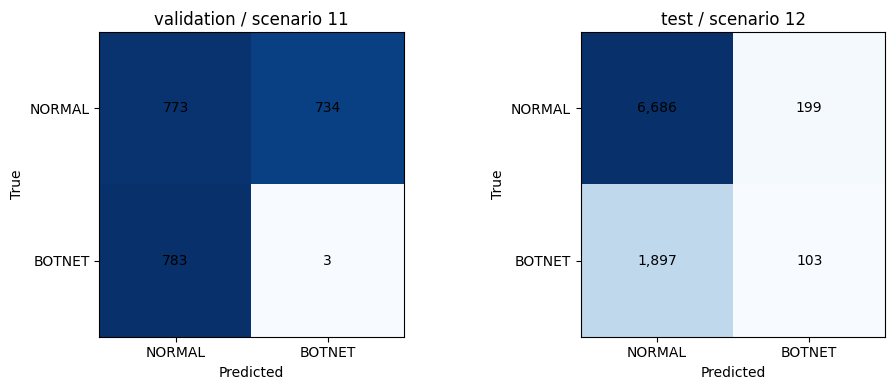

In [74]:
test_metrics=evaluate('test',model)
metrics=pd.DataFrame([{k:v for k,v in d.items() if k!='confusion_matrix'} for d in
                      [validation_metrics,test_metrics]])
display(metrics)
metrics.to_csv(OUTPUT/'scenario_holdout_metrics.csv',index=False)
(OUTPUT/'scenario_holdout_metrics.json').write_text(json.dumps({
    'validation':validation_metrics,'test':test_metrics},indent=2))
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,(key,data) in zip(axes,[('validation',validation_metrics),('test',test_metrics)]):
    cm=np.asarray(data['confusion_matrix'])
    ax.imshow(cm,cmap='Blues')
    ax.set_xticks([0,1],['NORMAL','BOTNET'])
    ax.set_yticks([0,1],['NORMAL','BOTNET'])
    ax.set_xlabel('Predicted');ax.set_ylabel('True');ax.set_title(f'{key} / scenario {data["scenario_id"]}')
    for r in range(2):
        for c in range(2):ax.text(c,r,f'{cm[r,c]:,}',ha='center',va='center',color='black')
plt.tight_layout();plt.savefig(OUTPUT/'ctu_flow_confusion_matrices.png',dpi=160);plt.show()

## 7. UNKNOWN flows và triển khai: ranh giới khả năng suy luận

Có thể chạy dự đoán thử trên UNKNOWN, nhưng **không tính đây là nhãn đúng/sai**. Các tỷ lệ dưới đây chỉ cho biết mô hình dự đoán gì trên dữ liệu chưa xác định nhãn; không phải Recall hay Accuracy. Để làm graph/beaconing thật cần bản dữ liệu CTU-13 gốc có địa chỉ IP, timestamp, hoặc export lại NetFlow đầy đủ.

In [75]:
unknown_summary=[]
for split,sid in SCENARIO_SPLIT.items():
    X=unknown_features[split]
    n=len(X)
    if n:
        for c in NUMERIC:X[c]=pd.to_numeric(X[c],errors='coerce').replace([np.inf,-np.inf],np.nan)
        for c in CATEGORICAL:X[c]=X[c].astype('object').where(X[c].notna(),np.nan)
        predicted_attack=0
        for start in range(0,n,10000):
            batch=X.iloc[start:start+10000]
            predicted_attack+=int((model.predict_proba(batch)[:,1]>=0.5).sum())
    else:predicted_attack=0
    unknown_summary.append({'split':split,'scenario_id':sid,'UNKNOWN_flows':n,
                            'predicted_BOTNET':predicted_attack,
                            'predicted_BOTNET_rate':float(predicted_attack/n) if n else None,
                            'note':'PREDICTIONS ONLY: UNKNOWN has no confirmed ground-truth label'})
display(pd.DataFrame(unknown_summary))
pd.DataFrame(unknown_summary).to_csv(OUTPUT/'unknown_prediction_audit.csv',index=False)

,split,scenario_id,UNKNOWN_flows,predicted_BOTNET,predicted_BOTNET_rate,note
0,train,5,87553,6647,0.075920,PREDICTIONS ONLY: UNKNOWN has no confirmed gro...
1,validation,11,70066,4623,0.065981,PREDICTIONS ONLY: UNKNOWN has no confirmed gro...
2,test,12,210032,13475,0.064157,PREDICTIONS ONLY: UNKNOWN has no confirmed gro...


## 8. Chốt báo cáo và điều kiện chuyển sang 07–08

In [76]:
manifest={
  'notebook':'06_CTU_Botnet_Graph_CORRECTED',
  'actual_task':'CTU-13 flow-based BOTNET vs NORMAL binary baseline',
  'scenarios':SCENARIO_SPLIT,'features':FEATURES,
  'excluded_leakage_columns':['label','Family','scenario_id','label_group'],
  'label_policy':{'from-botnet':'BOTNET','from-normal or normal-*':'NORMAL',
                  'background and other':'UNKNOWN — excluded from supervised metrics'},
  'graph_readiness':readiness,'validation_metrics':validation_metrics,
  'test_metrics':test_metrics,
  'limitations':[
    'Scenario-held-out only (5/11/12); not independent capture-domain evaluation',
    'Uncertain Background labels are not treated as NORMAL',
    'Host communication graph requires real src/dst IP; cannot synthesize from feature rows',
    'Beaconing and temporal ML require real timestamps and endpoints',
    'No direct comparison to multiclass CIC-IDS2017 metrics',
    'Supervised scores exclude UNKNOWN flows'
  ],
  'next_steps':{
    '07_Topology_Beaconing':'BLOCKED until source/destination IP + timestamp from raw CTU NetFlow or pcap',
    '08_CTU_Temporal_Training':'BLOCKED until reliable timestamp and grouping keys available',
    '09_Final_Evaluation':'Can report this flow-only CTU scenario-held-out baseline separately; do not claim graph/temporal results'}
}
(OUTPUT/'06_experiment_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False))
print('Saved outputs:')
for p in sorted(OUTPUT.iterdir()):print(' -',p.name, f'{p.stat().st_size:,} bytes')
print('Graph feasible?',graph_feasible,'| Beaconing feasible?',beacon_feasible)
print('NEXT: acquire CTU original IP/timestamps for 07 and 08, or formally revise those scopes.')

Saved outputs:
 - 06_experiment_manifest.json 3,424 bytes
 - ctu_flow_confusion_matrices.png 36,049 bytes
 - ctu_flow_only_rf.joblib 1,516,299 bytes
 - graph_feasibility.json 602 bytes
 - scenario_holdout_metrics.csv 599 bytes
 - scenario_holdout_metrics.json 1,322 bytes
 - scenario_label_coverage.csv 146 bytes
 - test_classification_report.csv 403 bytes
 - test_confusion_matrix.csv 67 bytes
 - test_labeled_predictions.csv 211,964 bytes
 - unknown_prediction_audit.csv 387 bytes
 - validation_classification_report.csv 419 bytes
 - validation_confusion_matrix.csv 63 bytes
 - validation_labeled_predictions.csv 53,907 bytes
Graph feasible? False | Beaconing feasible? False
NEXT: acquire CTU original IP/timestamps for 07 and 08, or formally revise those scopes.
